In [1]:
import sys
sys.path.append("..")
 
import json
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
from src.utils import get_distilbert_tokenizer
from transformers import DistilBertTokenizerFast
from tqdm import tqdm
 
tok = get_distilbert_tokenizer()


In [2]:
class ScorerDataset(Dataset):
    def __init__(self, path, tokenizer, max_len=256):
        self.samples = json.load(open(path))
        self.tok = tokenizer
        self.max_len = max_len

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        s = self.samples[idx]
        enc = self.tok(s["text"], truncation=True, max_length=self.max_len,
                       padding="max_length", return_tensors="pt")
        targets = torch.tensor(s["targets"][:self.max_len], dtype=torch.float)
        # pad targets to max_len
        pad_len = self.max_len - len(targets)
        targets = torch.cat([targets, torch.zeros(pad_len)])
        return {
            "input_ids": enc.input_ids.squeeze(),
            "attention_mask": enc.attention_mask.squeeze(),
            "targets": targets
        }

tok = DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")
ds = ScorerDataset("../data/train_samples.json", tok)
dl = DataLoader(ds, batch_size=16, shuffle=True)

In [3]:
import importlib
import src.scorer
importlib.reload(src.scorer)
from src.scorer import TokenScorer, load_scorer

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = TokenScorer(freeze_encoder=True).to(device)
opt = torch.optim.Adam(model.head.parameters(), lr=3e-4)



Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [5]:
losses = []
for epoch in range(3):
    for batch in tqdm(dl, desc=f"Epoch {epoch+1}"):
        ids  = batch["input_ids"].to(device)
        mask = batch["attention_mask"].to(device)
        tgt  = batch["targets"].to(device)
        pred = model(ids, mask)
        # only compute loss on non-padded positions
        loss = F.binary_cross_entropy(pred * mask.float(), tgt * mask.float())
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())

torch.save(model.state_dict(), "../models/scorer.pt")
print("Saved scorer.pt")

Epoch 1:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 1:   3%|▎         | 1/32 [00:03<01:44,  3.37s/it]

Epoch 1:   6%|▋         | 2/32 [00:06<01:33,  3.13s/it]

Epoch 1:   9%|▉         | 3/32 [00:09<01:26,  2.99s/it]

Epoch 1:  12%|█▎        | 4/32 [00:12<01:22,  2.93s/it]

...

Epoch 3:  94%|█████████▍| 30/32 [01:25<00:05,  2.88s/it]

Epoch 3:  97%|█████████▋| 31/32 [01:28<00:02,  2.86s/it]

Epoch 3: 100%|██████████| 32/32 [01:29<00:00,  2.22s/it]

Epoch 3: 100%|██████████| 32/32 [01:29<00:00,  2.79s/it]

Saved scorer.pt


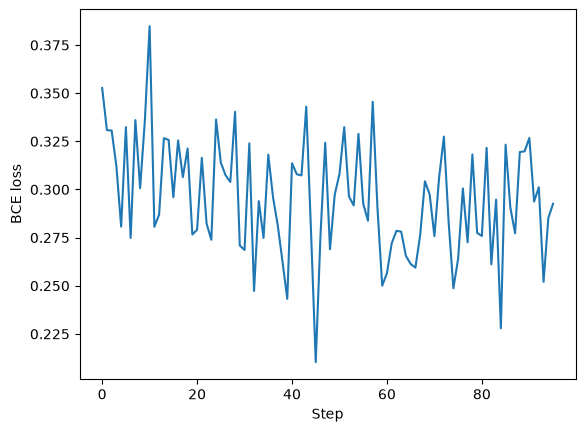

In [6]:
plt.plot(losses); plt.xlabel("Step"); plt.ylabel("BCE loss"); plt.show()
